In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

## IMPORT LIBRARIES

In [6]:
import os
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from PIL import Image

from torchvision import datasets, transforms

from sklearn.metrics import(
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully !")

All libraries imported successfully !


## set rabdom seed and device

In [9]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using decvice.", device)

Using decvice. cuda


In [17]:
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU: Tesla T4


## 1. Dataset Peparation

In [30]:
SRC = Path(
    "/kaggle/input/datasets/sanikamal/horses-or-humans-dataset"
)

DST = Path("horse_dataset")

random.seed(SEED)

extensions = {".png", ".jpg", ".jpeg"}

pool = {
    "horse": {},
    "not_horse": {}
}

# Collect images
for p in SRC.rglob("*"):

    if p.suffix.lower() in extensions:

        folder = p.parent.name.lower()

        if folder == "horses":
            pool["horse"][p.name] = p

        elif folder == "humans":
            pool["not_horse"][p.name] = p


# Remove previous dataset folder
if DST.exists():
    shutil.rmtree(DST)


# Create train, validation and test splits
for cls, files in pool.items():

    files = list(files.values())

    random.shuffle(files)

    n = len(files)

    n_train = int(0.70 * n)
    n_val = int(0.15 * n)

    splits = {
        "train": files[:n_train],

        "val": files[n_train:n_train+n_val],

        "test": files[n_train+n_val:]
    }

    for split, items in splits.items():

        output_folder = DST / split / cls

        output_folder.mkdir(
            parents=True,
            exist_ok=True
        )

        for f in items:

            shutil.copy2(
                f,
                output_folder / f.name
            )


# Check dataset
for split in ["train", "val", "test"]:

    for cls in ["horse", "not_horse"]:

        count = len(
            list((DST / split / cls).glob("*"))
        )

        print(split, cls, count)

train horse 439
train not_horse 458
val horse 94
val not_horse 98
test horse 95
test not_horse 99


## Image Preprocessing

In [45]:
train_transform = transforms.Compose([

    transforms.Resize((64, 64)),

    transforms.RandomHorizontalFlip(),

    transforms.ToTensor()

])


eval_transform = transforms.Compose([

    transforms.Resize((64, 64)),

    transforms.ToTensor()

])

## Load dataset

In [46]:
train_dataset = datasets.ImageFolder(
    "horse_dataset/train",
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    "horse_dataset/val",
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    "horse_dataset/test",
    transform=eval_transform
)


print("Class mapping:", train_dataset.class_to_idx)

print("Training images:", len(train_dataset))

print("Validation images:", len(val_dataset))

print("Testing images:", len(test_dataset))

Class mapping: {'horse': 0, 'not_horse': 1}
Training images: 897
Validation images: 192
Testing images: 194


## Create DataLoaders

In [47]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

## check image and label shape

In [53]:
images, labels = next(iter(train_loader))
print("images shape:", images.shape)
print("labels shape:", labels.shape)

images shape: torch.Size([32, 3, 64, 64])
labels shape: torch.Size([32])


## Visualize images

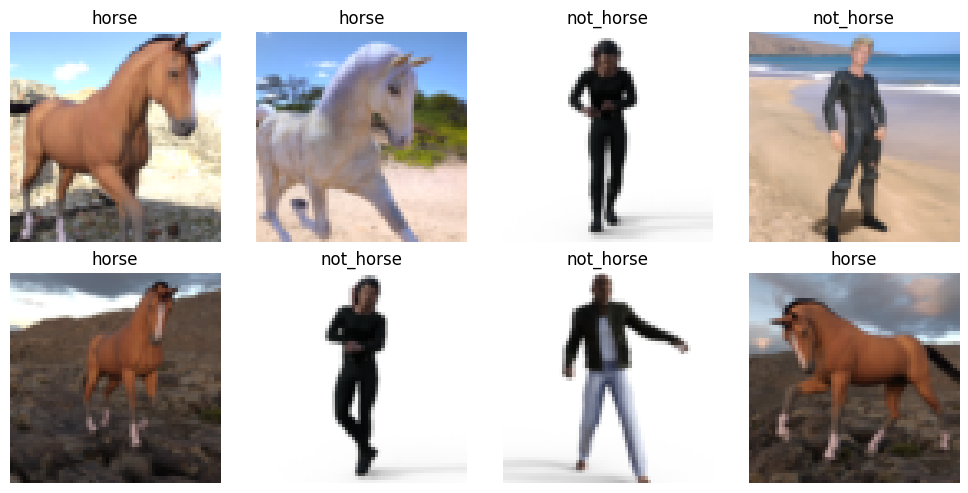

In [54]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(10, 5))

for i in range(8):

    plt.subplot(2, 4, i + 1)

    image = images[i].permute(1, 2, 0)

    plt.imshow(image)

    plt.title(
        train_dataset.classes[labels[i].item()]
    )

    plt.axis("off")

plt.tight_layout()

plt.show()

## Build ANN architecture

In [62]:
class HorseANN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            #Hidden layer 1
            nn.Linear(64 * 64 * 3, 512),
            nn.ReLU(),
            nn.Dropout(0.3),

            ##Hidden layer 2
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.2),

            ##outout layer
            nn.Linear(128, 2)
        )

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        x = self.network(x)
        return x

In [63]:
model = HorseANN().to(device)
print(model)

HorseANN(
  (network): Sequential(
    (0): Linear(in_features=12288, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=512, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=128, out_features=2, bias=True)
  )
)


## Calculate total parameters

In [67]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total parameters: ", total_params)
print("Trainable parameters: ", trainable_params)

Total parameters:  6357890
Trainable parameters:  6357890


## 12. Define loss and optimizer

In [68]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

## 13. Training Function

In [70]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer
):

    model.train()

    total_loss = 0

    correct = 0

    total = 0


    for images, labels in loader:

        images = images.to(device)

        labels = labels.to(device)


        # Clear old gradients
        optimizer.zero_grad()


        # Forward pass
        outputs = model(images)


        # Calculate loss
        loss = criterion(outputs, labels)


        # Backpropagation
        loss.backward()


        # Update weights
        optimizer.step()


        # Predictions
        predictions = outputs.argmax(dim=1)


        correct += (predictions == labels).sum().item()

        total += labels.size(0)


        total_loss += loss.item() * labels.size(0)


    epoch_loss = total_loss / total

    epoch_accuracy = correct / total * 100


    return epoch_loss, epoch_accuracy

## 14. Validation function

In [71]:
def validate(model, loader, criterion):

    model.eval()

    total_loss = 0

    correct = 0

    total = 0


    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            labels = labels.to(device)


            # Forward pass
            outputs = model(images)


            # Calculate loss
            loss = criterion(outputs, labels)


            # Predictions
            predictions = outputs.argmax(dim=1)


            correct += (predictions == labels).sum().item()

            total += labels.size(0)


            total_loss += loss.item() * labels.size(0)


    epoch_loss = total_loss / total

    epoch_accuracy = correct / total * 100


    return epoch_loss, epoch_accuracy

## 15. Train the ANN Model

In [72]:
epochs = 15

best_val_accuracy = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}


for epoch in range(epochs):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )


    val_loss, val_acc = validate(
        model,
        val_loader,
        criterion
    )


    history["train_loss"].append(train_loss)

    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)

    history["val_acc"].append(val_acc)


    print(f"\nEpoch: {epoch+1}/{epochs}")

    print(f"Train Loss: {train_loss:.4f}")

    print(f"Train Accuracy: {train_acc:.2f}%")

    print(f"Val Loss: {val_loss:.4f}")

    print(f"Val Accuracy: {val_acc:.2f}%")


    # Save best model
    if val_acc > best_val_accuracy:

        best_val_accuracy = val_acc

        torch.save(
            model.state_dict(),
            "best_horse_ann.pth"
        )

        print("Best model saved!")


    print("-" * 40)


Epoch: 1/15
Train Loss: 0.9312
Train Accuracy: 57.97%
Val Loss: 0.5822
Val Accuracy: 66.67%
Best model saved!
----------------------------------------

Epoch: 2/15
Train Loss: 0.7586
Train Accuracy: 60.31%
Val Loss: 0.6809
Val Accuracy: 56.25%
----------------------------------------

Epoch: 3/15
Train Loss: 0.6194
Train Accuracy: 64.10%
Val Loss: 0.5082
Val Accuracy: 71.35%
Best model saved!
----------------------------------------

Epoch: 4/15
Train Loss: 0.4760
Train Accuracy: 75.47%
Val Loss: 0.4392
Val Accuracy: 77.08%
Best model saved!
----------------------------------------

Epoch: 5/15
Train Loss: 0.4393
Train Accuracy: 78.93%
Val Loss: 0.3840
Val Accuracy: 79.69%
Best model saved!
----------------------------------------

Epoch: 6/15
Train Loss: 0.4069
Train Accuracy: 80.04%
Val Loss: 0.4412
Val Accuracy: 78.65%
----------------------------------------

Epoch: 7/15
Train Loss: 0.4814
Train Accuracy: 76.48%
Val Loss: 0.3725
Val Accuracy: 81.77%
Best model saved!
-------------

## 16. Plot training and validation loss

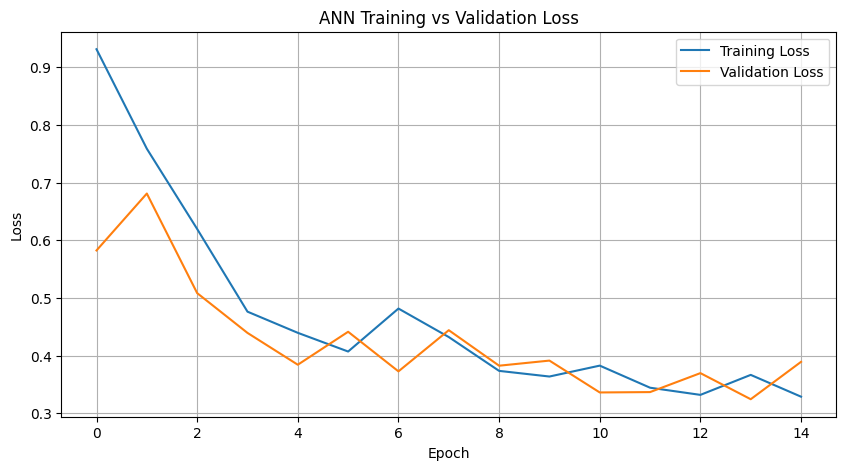

In [73]:
plt.figure(figsize=(10, 5))

plt.plot(
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("ANN Training vs Validation Loss")

plt.legend()

plt.grid()

plt.show()

## 17. Plot training and validation accuracy

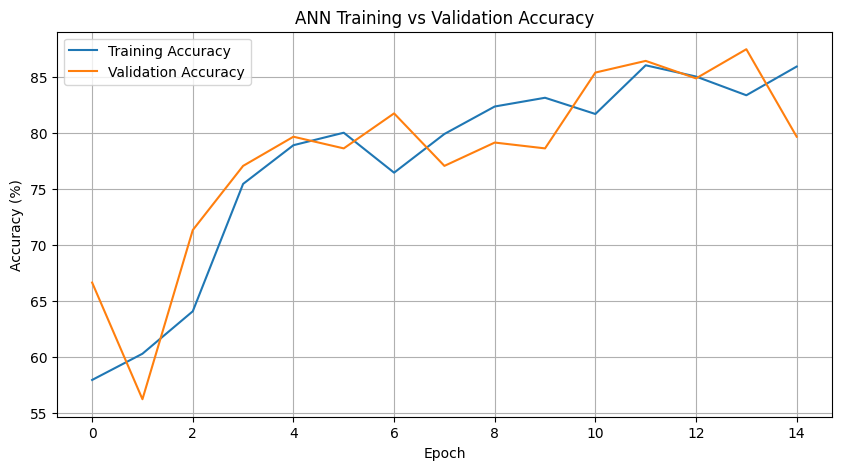

In [74]:
plt.figure(figsize=(10, 5))

plt.plot(
    history["train_acc"],
    label="Training Accuracy"
)

plt.plot(
    history["val_acc"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy (%)")

plt.title("ANN Training vs Validation Accuracy")

plt.legend()

plt.grid()

plt.show()

## 18. Load best model

In [75]:
model = HorseANN().to(device)

model.load_state_dict(
    torch.load("best_horse_ann.pth"
        
    )
)

model.to(device)
model.eval()

print("Best ANN Model loaded succesfully")

Best ANN Model loaded succesfully


In [77]:
test_loss, test_acc = validate(
    model, 
    test_loader, 
    criterion
)

print("Test loss:", test_loss)
print("Test accuracy: ", test_acc)

Test loss: 0.2977400655214934
Test accuracy:  86.08247422680412


## 20. Classification report and confusion matrix

In [79]:
all_predictions = []

all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)
        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            predictions.cpu().numpy()
        )

print(classification_report(
    all_labels,
    all_predictions,
    target_names = test_dataset.classes
))

              precision    recall  f1-score   support

       horse       1.00      1.00      1.00        84
   not_horse       1.00      1.00      1.00       110

    accuracy                           1.00       194
   macro avg       1.00      1.00      1.00       194
weighted avg       1.00      1.00      1.00       194



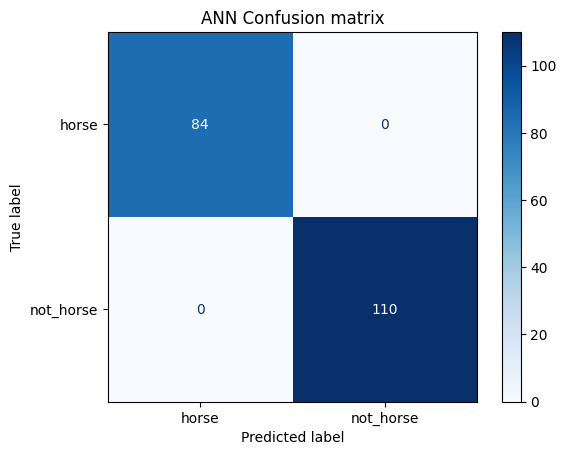

In [83]:
cm = confusion_matrix(
    all_labels,
    all_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=test_dataset.classes
)

disp.plot(cmap= "Blues")

plt.title("ANN Confusion matrix")

plt.show()

## 21. save final model

In [84]:
torch.save(
    model.state_dict(),
    "best_horse_ann.pth"
)

print("ANN model saved succesfully")

ANN model saved succesfully


## 22. Single-image prediction

In [88]:
image_path = "/kaggle/input/datasets/uniabhi/horse-data/frame_0115.jpg"

image = Image.open(image_path).convert("RGB")


image_tensor = eval_transform(image)


# Add batch dimension
image_tensor = image_tensor.unsqueeze(0)


image_tensor = image_tensor.to(device)


model.eval()

with torch.no_grad():

    output = model(image_tensor)

    prediction = output.argmax(dim=1).item()


class_names = train_dataset.classes

print("Prediction:", class_names[prediction])

Prediction: horse
